
---
date: "2026-11-07"
date-modified: last-modified
format:
  html:
    toc: true
---


# Orthogonality, Projections and the Gram–Schmidt Process

**Prerequisites:** [Inner Product Spaces and the Cauchy-Schwarz Inequality](Cauchy-Schwarz-inequality.ipynb) · [Basis and Dimension](basis-and-dimension.ipynb) · [Affine Subspaces](affine-subspaces.ipynb) · [Eigenvalues and Eigenvectors](eigenvalues-and-eigenvectors.ipynb)

Throughout, $\mathbb{R}^n$ carries the dot product $u\cdot v = \sum_{i=1}^n u_iv_i$ and the length $|u| = \sqrt{u\cdot u}$; $d(x, y) = |x - y|$. The Cauchy–Schwarz inequality $|u\cdot v| \le |u|\,|v|$ holds, with equality iff $u, v$ are linearly dependent.

## 1\. Angles and Orthogonality

::: {#def-angle}
## Angle, Orthogonality

For $u, v \ne 0$ the **angle** between them is $\angle(u, v) = \arccos\dfrac{u\cdot v}{|u|\,|v|} \in [0, \pi]$ (the quotient lies in $[-1, 1]$ by Cauchy–Schwarz). $u$ and $v$ are **orthogonal**, $u \perp v$, if $u\cdot v = 0$.
:::

::: {#prp-pythagoras}
## Pythagoras, Law of Cosines, Triangle Inequality

For $u, v \in \mathbb{R}^n$:

1. $|u + v|^2 = |u|^2 + 2\,u\cdot v + |v|^2$; in particular $|u + v|^2 = |u|^2 + |v|^2$ iff $u \perp v$.
2. For $u, v \ne 0$: $|u - v|^2 = |u|^2 + |v|^2 - 2|u|\,|v|\cos\angle(u, v)$.
3. $|u + v| \le |u| + |v|$, with equality iff one of $u, v$ is a non-negative multiple of the other.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-pythagoras
(1) Expand $(u + v)\cdot(u + v)$ by bilinearity and symmetry. (2) Replace $v$ by $-v$ in (1) and use $u\cdot v = |u|\,|v|\cos\angle(u, v)$.
(3) By (1) and Cauchy–Schwarz, $|u + v|^2 \le |u|^2 + 2|u|\,|v| + |v|^2 = (|u| + |v|)^2$. Equality forces $u\cdot v = |u|\,|v|$: equality in Cauchy–Schwarz, so (if $v \ne 0$) $u = tv$, and then $t|v|^2 = |t|\,|v|^2$ gives $t \ge 0$. $\blacksquare$
:::

## 2\. Projection onto a Line

::: {#prp-projection-line}
## Orthogonal Projection onto a Line

Let $v \ne 0$. Every $u$ can be written uniquely as $u = u' + u''$ with $u' \parallel v$ and $u'' \perp v$, namely
$$u' = \frac{u\cdot v}{|v|^2}\,v .$$
Moreover $u'$ is the unique point of the line $\mathbb{R}v$ nearest to $u$. Consequently, the point of the line $\{a + tA\}$ ($A \ne 0$) nearest to $p$ is $q = a + \dfrac{(p - a)\cdot A}{|A|^2}A$, and the distance from $p$ to the line is $|p - q|$.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-projection-line
If $u = tv + u''$ with $u''\cdot v = 0$, dotting with $v$ gives $u\cdot v = t|v|^2$, so $t$ is forced; and with this $t$, $u - tv \perp v$. For any $s$, $u - sv = u'' + (t - s)v$ with $u'' \perp v$, so by Pythagoras $|u - sv|^2 = |u''|^2 + (t - s)^2|v|^2$, minimal exactly at $s = t$. For the line $a + tA$ apply this to $u = p - a$, $v = A$. $\blacksquare$
:::

::: {#exm-distance-point-line}
## Distance from a Point to a Line in $\mathbb{R}^4$

The line $\frac{x_1}{2} = \frac{x_2 - 1}{1} = \frac{x_3 + 1}{-1} = \frac{x_4}{3}$ is $a + tA$ with $a = (0, 1, -1, 0)$, $A = (2, 1, -1, 3)$. For $p = (1, -1, 0, 2)$: $(p - a)\cdot A = 5$, $|A|^2 = 15$, so the nearest point is $q = a + \frac13A = \big(\frac23, \frac43, -\frac43, 1\big)$ and the distance is $|p - q| = \big|\big(\frac13, -\frac73, \frac43, 1\big)\big| = \frac{5}{\sqrt3}$.
:::

## 3\. Orthonormal Bases and Gram–Schmidt

::: {#def-orthonormal}
## Orthogonal and Orthonormal Sets

Vectors $b_1, \dots, b_k$ are **orthogonal** if $b_i \perp b_j$ for $i \ne j$, and **orthonormal** if moreover $|b_i| = 1$, i.e. $b_i\cdot b_j = \delta_{ij}$.
:::

::: {#prp-orthogonal-independent}
## Orthogonal Vectors Are Independent

Non-zero orthogonal vectors are linearly independent. If $b_1, \dots, b_n$ is an orthonormal basis of $\mathbb{R}^n$, then for every $x$
$$x = \sum_{i=1}^n (x\cdot b_i)\,b_i, \qquad |x|^2 = \sum_{i=1}^n (x\cdot b_i)^2 .$$
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-orthogonal-independent
If $\sum c_ib_i = 0$, dot with $b_j$: $c_j|b_j|^2 = 0$, so $c_j = 0$. If $x = \sum c_ib_i$, dotting with $b_j$ gives $c_j = x\cdot b_j$, and $|x|^2 = \sum_{i,j}c_ic_j\,b_i\cdot b_j = \sum c_i^2$. $\blacksquare$
:::

::: {#thm-gram-schmidt}
## Gram–Schmidt Orthonormalization

Let $A_1, \dots, A_k$ be linearly independent. Define recursively
$$B'_j = A_j - \sum_{i<j}(A_j\cdot b_i)\,b_i, \qquad b_j = \frac{B'_j}{|B'_j|}\quad (j = 1, \dots, k).$$
Then $B'_j \ne 0$, the $b_j$ are orthonormal, and $\operatorname{span}\{b_1, \dots, b_j\} = \operatorname{span}\{A_1, \dots, A_j\}$ for every $j$.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-gram-schmidt
Induction on $j$. Suppose $b_1, \dots, b_{j-1}$ are orthonormal and span $V_{j-1} = \operatorname{span}\{A_1, \dots, A_{j-1}\}$. Then $B'_j \in A_j + V_{j-1}$, and $B'_j \ne 0$ since $A_j \notin V_{j-1}$. For $l < j$, $B'_j\cdot b_l = A_j\cdot b_l - A_j\cdot b_l = 0$. So $b_1, \dots, b_j$ are orthonormal; they lie in $V_j$, and being $j$ independent vectors (@prp-orthogonal-independent) in the $j$-dimensional $V_j$ they span it. $\blacksquare$
:::

::: {#cor-extend-orthonormal}
## Orthonormal Bases Exist and Extend

Every subspace $W \ne \{0\}$ of $\mathbb{R}^n$ has an orthonormal basis, and every orthonormal set $b_1, \dots, b_k$ in $\mathbb{R}^n$ extends to an orthonormal basis $b_1, \dots, b_n$.
:::

::: {.callout-tip collapse="true"}
## Proof of @cor-extend-orthonormal
Apply @thm-gram-schmidt to a basis of $W$. For the second claim, [extend](basis-and-dimension.ipynb) $b_1, \dots, b_k$ to a basis $b_1, \dots, b_k, A_{k+1}, \dots, A_n$ and apply Gram–Schmidt; the first $k$ vectors are unchanged because they are already orthonormal. $\blacksquare$
:::

::: {#exm-gram-schmidt}
## Gram–Schmidt in $\mathbb{R}^4$

$A_1 = (0, 0, -1, 1)$, $A_2 = (1, 0, 2, 0)$, $A_3 = (1, 1, 3, 0)$. Working with the unnormalized $B'_j$ (so $(A_j\cdot b_i)b_i = \frac{A_j\cdot B'_i}{|B'_i|^2}B'_i$):

* $B'_1 = A_1$, $|B'_1|^2 = 2$;
* $B'_2 = A_2 - \frac{-2}{2}B'_1 = (1, 0, 1, 1)$, $|B'_2|^2 = 3$;
* $B'_3 = A_3 - \frac{-3}{2}B'_1 - \frac{4}{3}B'_2 = \big(-\frac13, 1, \frac16, \frac16\big)$, $|B'_3|^2 = \frac{7}{6}$.

So $b_1 = \frac{1}{\sqrt2}(0, 0, -1, 1)$, $b_2 = \frac{1}{\sqrt3}(1, 0, 1, 1)$, $b_3 = \frac{1}{\sqrt{42}}(-2, 6, 1, 1)$.
:::

## 4\. Orthogonal Complements and Equations of Flats

::: {#prp-orthogonal-complement}
## Orthogonal Complement and Projection

For a subspace $W$ of $\mathbb{R}^n$ let $W^\perp = \{x : x\cdot w = 0 \text{ for all } w \in W\}$. Then $\mathbb{R}^n = W \oplus W^\perp$, $\dim W^\perp = n - \dim W$ and $(W^\perp)^\perp = W$. If $b_1, \dots, b_k$ is an orthonormal basis of $W$, the **orthogonal projection** $P_Wx = \sum_{i=1}^k (x\cdot b_i)b_i$ is the unique point of $W$ nearest to $x$, and $x - P_Wx \in W^\perp$.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-orthogonal-complement
Extend $b_1, \dots, b_k$ to an orthonormal basis $b_1, \dots, b_n$ (@cor-extend-orthonormal). By @prp-orthogonal-independent, $x \in W^\perp$ iff $x\cdot b_i = 0$ for $i \le k$ iff $x \in \operatorname{span}\{b_{k+1}, \dots, b_n\}$. Hence $W^\perp = \operatorname{span}\{b_{k+1}, \dots, b_n\}$, which gives the direct sum, the dimension, and (by symmetry of the roles) $(W^\perp)^\perp = W$. Writing $x = P_Wx + (x - P_Wx)$ with $x - P_Wx = \sum_{i>k}(x\cdot b_i)b_i \in W^\perp$, for $w \in W$ Pythagoras gives $|x - w|^2 = |x - P_Wx|^2 + |P_Wx - w|^2$, minimal iff $w = P_Wx$. $\blacksquare$
:::

::: {#prp-flat-equations}
## Equations of Hyperplanes and Flats

A $k$-dimensional affine subspace $p + W$ of $\mathbb{R}^n$ is the solution set of $n - k$ linear equations
$$B_j\cdot(x - p) = 0, \qquad j = 1, \dots, n - k,$$
where $B_1, \dots, B_{n-k}$ is any basis of $W^\perp$. In particular every hyperplane ($k = n - 1$) is $\{x : C\cdot(x - p) = 0\} = \{x : C\cdot x = C\cdot p\}$ for a **normal vector** $C \ne 0$, and the distance from $q$ to it is $\dfrac{|C\cdot(q - p)|}{|C|}$.
:::

::: {.callout-tip collapse="true"}
## Proof of @prp-flat-equations
$x - p \in W = (W^\perp)^\perp$ iff $x - p$ is orthogonal to each $B_j$. For the distance, the nearest point of the hyperplane to $q$ is $q - \frac{C\cdot(q - p)}{|C|^2}C$ by @prp-orthogonal-complement applied to $q - p$ and $W = C^\perp$ (whose complement is $\mathbb{R}C$), so the distance is the length of the projection of $q - p$ on $C$. $\blacksquare$
:::

## 5\. Symmetric Matrices

A real $n\times n$ matrix $A$ is **symmetric** if $A^{\mathsf T} = A$, equivalently $(Ax)\cdot y = x\cdot(Ay)$ for all $x, y$. A matrix $Q$ is **orthogonal** if its columns form an orthonormal basis, i.e. $Q^{\mathsf T}Q = I$.

::: {#thm-real-spectral}
## Spectral Theorem for Real Symmetric Matrices

If $A$ is real symmetric, all its eigenvalues are real and $\mathbb{R}^n$ has an orthonormal basis of eigenvectors of $A$. Equivalently $A = Q\Lambda Q^{\mathsf T}$ with $Q$ orthogonal and $\Lambda$ diagonal.
:::

::: {.callout-tip collapse="true"}
## Proof of @thm-real-spectral
*Real eigenvalues.* The characteristic polynomial has a complex root $\lambda$ ([fundamental theorem of algebra](eigenvalues-and-eigenvectors.ipynb#def-algebraically-closed-field)); take $v \in \mathbb{C}^n \setminus \{0\}$ with $Av = \lambda v$. Then $\bar v^{\mathsf T}Av = \lambda\,\bar v^{\mathsf T}v = \lambda\sum|v_i|^2$, and conjugating, $\overline{\bar v^{\mathsf T}Av} = v^{\mathsf T}A\bar v = (v^{\mathsf T}A\bar v)^{\mathsf T} = \bar v^{\mathsf T}A v$ since $A$ is real symmetric. So $\lambda\sum|v_i|^2$ is real and $\lambda \in \mathbb{R}$; then $A - \lambda I$ is a singular real matrix and has a real non-zero kernel vector.

*Orthonormal eigenbasis.* Induction on $n$. Let $b_1$ be a real unit eigenvector, $Ab_1 = \lambda_1b_1$, and $W = b_1^\perp$. If $w \in W$ then $(Aw)\cdot b_1 = w\cdot Ab_1 = \lambda_1\,w\cdot b_1 = 0$, so $A(W) \subseteq W$. In an orthonormal basis $c_2, \dots, c_n$ of $W$ the restriction of $A$ has matrix $\big((Ac_j)\cdot c_i\big)$, which is symmetric; by induction $W$ has an orthonormal basis $b_2, \dots, b_n$ of eigenvectors. Then $b_1, \dots, b_n$ is the required basis, and $Q = [b_1 \cdots b_n]$ gives $AQ = Q\Lambda$. $\blacksquare$
:::

::: {#cor-quadratic-form-bounds}
## Quadratic Forms

Let $A$ be real symmetric with eigenvalues $\lambda_{\min} = \lambda_1 \le \dots \le \lambda_n = \lambda_{\max}$ and $q(x) = x^{\mathsf T}Ax = \sum_{i,j}a_{ij}x_ix_j$. In the coordinates $y = Q^{\mathsf T}x$ of the eigenbasis, $q(x) = \sum_i \lambda_iy_i^2$, hence
$$\lambda_{\min}|x|^2 \le q(x) \le \lambda_{\max}|x|^2 .$$
So $q(x) > 0$ for all $x \ne 0$ iff all $\lambda_i > 0$, and $q$ takes both signs iff $A$ has eigenvalues of both signs.
:::

::: {.callout-tip collapse="true"}
## Proof of @cor-quadratic-form-bounds
$x = Qy$ gives $q(x) = y^{\mathsf T}Q^{\mathsf T}AQy = y^{\mathsf T}\Lambda y = \sum\lambda_iy_i^2$, and $|y| = |x|$ by @prp-orthogonal-independent. Bound each $\lambda_i$ by $\lambda_{\min}$, $\lambda_{\max}$; the sign statements follow by taking $y = e_i$. $\blacksquare$
:::

B'_j: [[0, 0, -1, 1], [1, 0, 1, 1], [-1/3, 1, 1/6, 1/6]] | |B'_j|^2: [2, 3, 7/6]
pairwise dot products: [0, 0, 0]
nearest point: [2/3, 4/3, -4/3, 1] | distance: 5*sqrt(3)/3


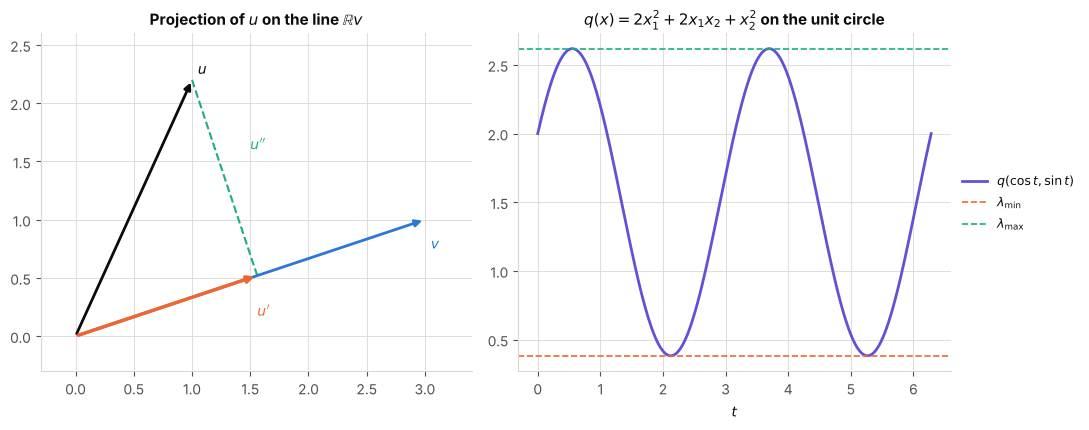

eigenvalues: [0.38196601 2.61803399] | Q^T Q = [[1.0, -0.0], [-0.0, 1.0]]


In [1]:

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW, VIOLET, RED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#6250d6", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#d9d8d4"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white",
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "legend.frameon": False, "font.size": 10})

# Gram-Schmidt example
A = [sp.Matrix([0, 0, -1, 1]), sp.Matrix([1, 0, 2, 0]), sp.Matrix([1, 1, 3, 0])]
B = []
for a in A:
    b = a - sum(((a.dot(c) / c.dot(c)) * c for c in B), sp.zeros(4, 1))
    B.append(b)
print("B'_j:", [list(b) for b in B], "| |B'_j|^2:", [b.dot(b) for b in B])
print("pairwise dot products:", [B[i].dot(B[j]) for i in range(3) for j in range(i + 1, 3)])
# distance example
a, Av, p = sp.Matrix([0, 1, -1, 0]), sp.Matrix([2, 1, -1, 3]), sp.Matrix([1, -1, 0, 2])
q = a + ((p - a).dot(Av) / Av.dot(Av)) * Av
print("nearest point:", list(q), "| distance:", sp.nsimplify(sp.sqrt((p - q).dot(p - q))))

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 4.4))
u, v = np.array([1.0, 2.2]), np.array([3.0, 1.0])
up = u @ v / (v @ v) * v
ax.annotate("", xy=v, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=BLUE, lw=2))
ax.annotate("", xy=u, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=INK, lw=2))
ax.annotate("", xy=up, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color=ORANGE, lw=2.5))
ax.plot([u[0], up[0]], [u[1], up[1]], color=AQUA, lw=1.5, ls="--")
ax.text(*(v + [0.05, -0.25]), "$v$", color=BLUE); ax.text(*(u + [0.05, 0.05]), "$u$")
ax.text(*(up + [0.0, -0.35]), "$u'$", color=ORANGE); ax.text(1.5, 1.6, "$u''$", color=AQUA)
ax.set_xlim(-0.3, 3.4); ax.set_ylim(-0.3, 2.6); ax.set_aspect("equal")
ax.set_title("Projection of $u$ on the line $\\mathbb{R}v$")

S = np.array([[2.0, 1.0], [1.0, 1.0]])
lam, Q = np.linalg.eigh(S)
t = np.linspace(0, 2 * np.pi, 400)
X = np.stack([np.cos(t), np.sin(t)])
qv = np.einsum("in,ij,jn->n", X, S, X)
ax2.plot(t, qv, color=VIOLET, lw=2, label=r"$q(\cos t, \sin t)$")
ax2.axhline(lam[0], color=ORANGE, ls="--", lw=1.2, label=r"$\lambda_{\min}$")
ax2.axhline(lam[1], color=AQUA, ls="--", lw=1.2, label=r"$\lambda_{\max}$")
ax2.set_xlabel("$t$"); ax2.legend(fontsize=9, loc="center left", bbox_to_anchor=(1.0, 0.5))
ax2.set_title(r"$q(x) = 2x_1^2 + 2x_1x_2 + x_2^2$ on the unit circle")
plt.tight_layout(); plt.show()
print("eigenvalues:", lam, "| Q^T Q =", np.round(Q.T @ Q, 12).tolist())